<a href="https://colab.research.google.com/github/ShreyaBawankar77/Hack-O-Week/blob/main/Week11_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

In [ ]:
wine = load_wine()

X = wine.data
y = wine.target

feature_names = wine.feature_names
target_names = wine.target_names

df = pd.DataFrame(X, columns=feature_names)
df["target"] = y

df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [ ]:
print("Dataset shape:", X.shape)
print("Number of features:", X.shape[1])
print("Number of samples:", X.shape[0])
print("Classes:", target_names)

Dataset shape: (178, 13)
Number of features: 13
Number of samples: 178
Classes: ['class_0' 'class_1' 'class_2']


In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
 13  targe

In [ ]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Original shape:", X.shape)
print("Scaled shape:", X_scaled.shape)

Original shape: (178, 13)
Scaled shape: (178, 13)


In [ ]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Original dimensions:", X.shape[1])
print("Reduced dimensions:", X_pca.shape[1])

Original dimensions: 13
Reduced dimensions: 2


In [ ]:
print("Explained variance ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal variance retained:")
print(pca.explained_variance_ratio_.sum())

Explained variance ratio:
[0.36198848 0.1920749 ]

Total variance retained:
0.5540633835693526


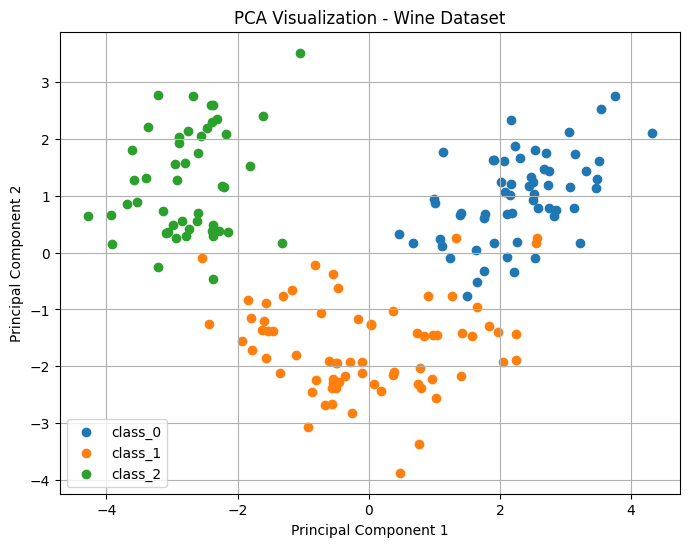

In [ ]:
plt.figure(figsize=(8, 6))

for i, target_name in enumerate(target_names):
    plt.scatter(
        X_pca[y == i, 0],
        X_pca[y == i, 1],
        label=target_name
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization - Wine Dataset")
plt.legend()
plt.grid()
plt.show()

In [ ]:
tsne = TSNE(
    n_components=2,
    perplexity=30,
    random_state=42
)

X_tsne = tsne.fit_transform(X_scaled)

print("Original dimensions:", X.shape[1])
print("Reduced dimensions:", X_tsne.shape[1])

Original dimensions: 13
Reduced dimensions: 2


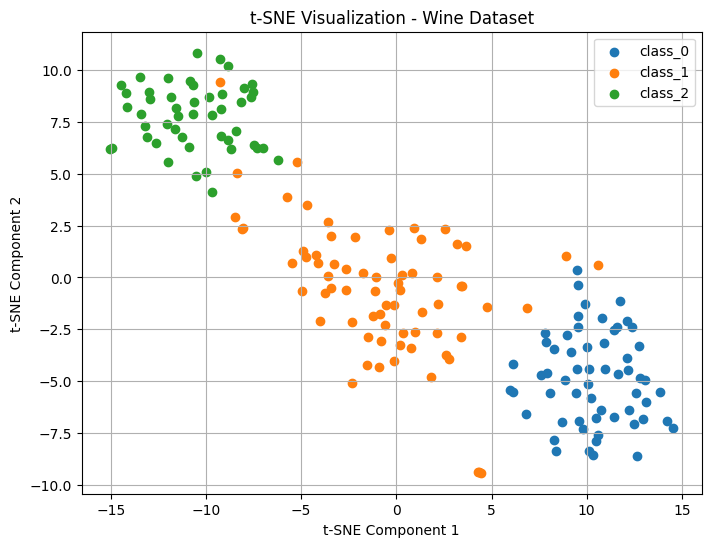

In [ ]:
plt.figure(figsize=(8, 6))

for i, target_name in enumerate(target_names):
    plt.scatter(
        X_tsne[y == i, 0],
        X_tsne[y == i, 1],
        label=target_name
    )

plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.title("t-SNE Visualization - Wine Dataset")
plt.legend()
plt.grid()
plt.show()

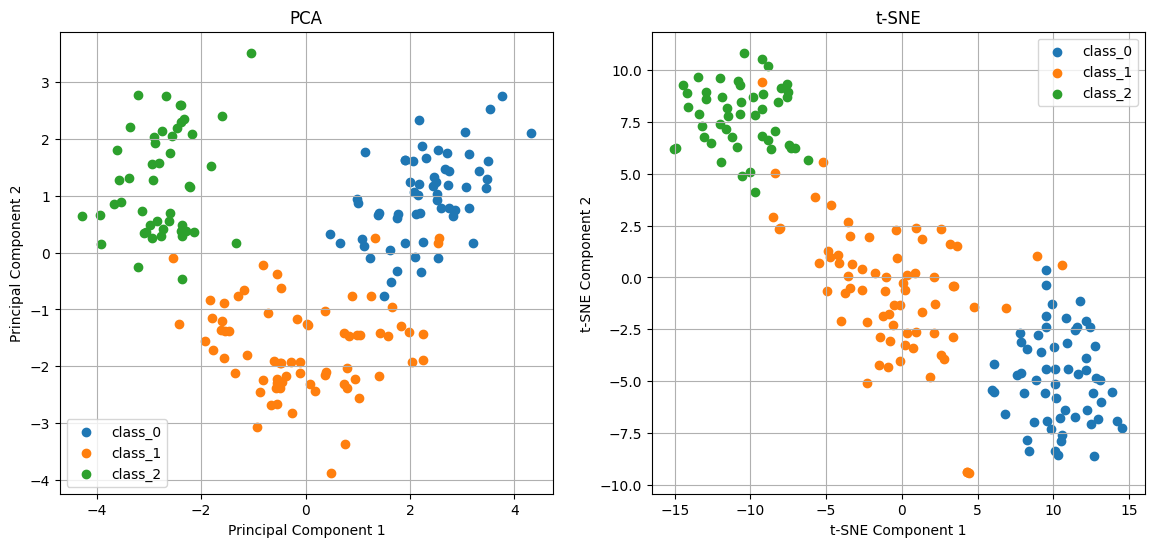

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# PCA
for i, target_name in enumerate(target_names):
    axes[0].scatter(
        X_pca[y == i, 0],
        X_pca[y == i, 1],
        label=target_name
    )

axes[0].set_title("PCA")
axes[0].set_xlabel("Principal Component 1")
axes[0].set_ylabel("Principal Component 2")
axes[0].grid()

# t-SNE
for i, target_name in enumerate(target_names):
    axes[1].scatter(
        X_tsne[y == i, 0],
        X_tsne[y == i, 1],
        label=target_name
    )

axes[1].set_title("t-SNE")
axes[1].set_xlabel("t-SNE Component 1")
axes[1].set_ylabel("t-SNE Component 2")
axes[1].grid()

axes[0].legend()
axes[1].legend()

plt.show()

In [ ]:
comparison = pd.DataFrame({
    "Method": ["PCA", "t-SNE"],
    "Type": ["Linear", "Non-linear"],
    "Original Dimensions": [13, 13],
    "Reduced Dimensions": [2, 2],
    "Main Purpose": [
        "Dimensionality reduction and visualization",
        "High-dimensional data visualization"
    ]
})

comparison

,Method,Type,Original Dimensions,Reduced Dimensions,Main Purpose
0,PCA,Linear,13,2,Dimensionality reduction and visualization
1,t-SNE,Non-linear,13,2,High-dimensional data visualization


In [ ]:
print("DIMENSIONALITY REDUCTION SUMMARY")
print("----------------------------------")
print("Dataset: Wine Recognition Dataset")
print("Original dimensions:", X.shape[1])
print("PCA dimensions:", X_pca.shape[1])
print("t-SNE dimensions:", X_tsne.shape[1])
print("Number of samples:", X.shape[0])
print("Number of classes:", len(target_names))

DIMENSIONALITY REDUCTION SUMMARY
----------------------------------
Dataset: Wine Recognition Dataset
Original dimensions: 13
PCA dimensions: 2
t-SNE dimensions: 2
Number of samples: 178
Number of classes: 3
